# GARCH(1,1) — Model Pembanding Klasik untuk Prediksi Volatilitas
## Prediksi Volatilitas Return Saham Sektor Energi LQ45

**Tesis**: Pemodelan Prediksi Volatilitas Return Saham Sektor Energi (LQ45) Berdasarkan Analisis Sentimen Menggunakan Metode XGBoost dan LSTM

**Penulis**: Ilda Nurida (NRP 6032251068) | **Pembimbing**: Dr. Ir. Ahmad Saikhu, S.Si, MT.

---

### Tujuan Notebook
GARCH(1,1) (Bollerslev, 1986) adalah model ekonometrika klasik paling banyak dirujuk untuk volatilitas keuangan. Notebook ini membangunnya sebagai **pembanding** (bukan ground truth) terhadap XGBoost dan LSTM — untuk menunjukkan apakah kompleksitas tambahan (fitur teknikal + sentimen berita, machine learning) benar-benar memberi nilai tambah dibanding pendekatan time-series klasik yang hanya memakai data return historis.

### Spesifikasi Model
$$r_t = \mu + \epsilon_t, \quad \epsilon_t = \sigma_t z_t, \quad z_t \sim N(0,1)$$
$$\sigma_t^2 = \omega + \alpha \epsilon_{t-1}^2 + \beta \sigma_{t-1}^2$$

GARCH(1,1) **polos** — hanya dari `Log_Return` historis (univariate), TANPA fitur teknikal maupun sentimen. Ini sengaja dijadikan kontrol yang adil: kalau XGBoost/LSTM (dengan fitur jauh lebih kaya) mengungguli GARCH, itu bukti kuantitatif bahwa integrasi sentimen & indikator teknikal benar-benar bernilai tambah.

### Metodologi Walk-Forward (Anti-Leakage)
GARCH di-**refit setiap hari** dengan *expanding window* (semua data historis sampai hari t-1), lalu forecast 1 hari ke depan (H+1) — **bukan** fit sekali di seluruh data lalu forecast berkali-kali (itu akan memakai parameter yang "melihat" masa depan test set, leakage). Ini lebih mahal komputasi tapi metodologinya benar.

### Catatan Perbandingan dengan Y (Volatilitas_Target)
Y di pipeline ini adalah **realized volatility** (rolling 20 hari), sedangkan GARCH menghasilkan **conditional volatility** 1-hari-kedepan — dua konstruk yang berbeda tapi keduanya proksi dari volatilitas "sebenarnya" yang tidak teramati langsung. Membandingkan forecast GARCH terhadap realized volatility sebagai target evaluasi adalah praktik standar di literatur (Patton, 2011) — QLIKE loss function secara spesifik didesain untuk skenario ini.

---
## CELL 1 — Import, Konfigurasi, dan Instalasi Library `arch`

In [1]:
import os, warnings
warnings.filterwarnings('ignore')

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

try:
    from arch import arch_model
except ImportError:
    raise ImportError("Library 'arch' belum terinstall. Jalankan: pip install arch")

SEED = 42
np.random.seed(SEED)

# ── ROOT auto-detect (identik notebook lain) ──
ROOT = Path(os.getcwd())
for _ in range(6):
    if (ROOT / '03_dataset').exists(): break
    ROOT = ROOT.parent
if not (ROOT / '03_dataset').exists():
    ROOT = Path(r'e:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS'
                r'\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026')

DIR_PROCESSED = ROOT / '03_dataset' / 'processed'
DIR_FINAL     = ROOT / '03_dataset' / 'final'
DIR_TABEL     = ROOT / '06_dokumen_tesis' / 'tabel'
DIR_GAMBAR    = ROOT / '06_dokumen_tesis' / 'gambar' / 'model'
for d in (DIR_TABEL, DIR_GAMBAR):
    d.mkdir(parents=True, exist_ok=True)

URUTAN_EMITEN = ['ADRO', 'ADMR', 'ITMG', 'PTBA', 'MEDC', 'AKRA', 'PGAS']
KOLOM_Y = 'Volatilitas_Target'   # HARUS sama dgn pipeline XGBoost/LSTM utk perbandingan adil
SPLIT_RATIO = 0.80               # sama dgn PREP_03 -- split kronologis 80:20
LOOKBACK = 10                    # samakan dgn LSTM, utk selaraskan sampel evaluasi [LOOKBACK:]
REFIT_SETIAP = 1                 # 1 = refit tiap hari (paling rigorous, default)

print('=' * 75)
print('  GARCH(1,1) -- KONFIGURASI SIAP')
print('=' * 75)
print(f'ROOT       : {ROOT}')
print(f'Emiten     : {URUTAN_EMITEN}')
print(f'KOLOM_Y    : {KOLOM_Y}')
print(f'Split      : {SPLIT_RATIO:.0%} train / {1-SPLIT_RATIO:.0%} test (kronologis)')
print(f'Refit      : setiap {REFIT_SETIAP} hari (expanding window, anti-leakage)')
print('=' * 75)


  GARCH(1,1) -- KONFIGURASI SIAP
ROOT       : e:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026
Emiten     : ['ADRO', 'ADMR', 'ITMG', 'PTBA', 'MEDC', 'AKRA', 'PGAS']
KOLOM_Y    : Volatilitas_Target
Split      : 80% train / 20% test (kronologis)
Refit      : setiap 1 hari (expanding window, anti-leakage)


---
## CELL 2 — Fungsi Bantu: Metrik Evaluasi (identik seluruh notebook lain)

In [2]:
def evaluasi_semua_metrik(y_true, y_pred):
    """RMSE, MAE, MAPE, R2, QLIKE -- rumus identik MODEL_xgboost_v2/MODEL_lstm_v3/
    EVALUASI_perbandingan_v4, supaya angka bisa dibandingkan langsung apple-to-apple."""
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)

    rmse = float(np.sqrt(mean_squared_error(y_true, y_pred)))
    mae  = float(mean_absolute_error(y_true, y_pred))

    mask_mape = y_true != 0
    mape = float(np.mean(np.abs((y_true[mask_mape] - y_pred[mask_mape]) / y_true[mask_mape])) * 100) \
           if mask_mape.sum() > 0 else np.nan

    r2 = float(r2_score(y_true, y_pred)) if len(y_true) > 1 else np.nan

    eps = 1e-10
    rasio = np.clip(y_true, eps, None) / np.clip(y_pred, eps, None)
    qlike = float(np.mean(rasio - np.log(rasio) - 1))

    return {'RMSE': rmse, 'MAE': mae, 'MAPE (%)': mape, 'R2': r2, 'QLIKE': qlike}


def interpretasi_mape(mape):
    if mape < 10: return 'Sangat Baik'
    elif mape < 20: return 'Baik'
    elif mape < 50: return 'Wajar'
    else: return 'Kurang Baik'


print('Fungsi evaluasi_semua_metrik & interpretasi_mape siap (identik pipeline lain).')


Fungsi evaluasi_semua_metrik & interpretasi_mape siap (identik pipeline lain).


---
## CELL 3 — Load Data & Split Train/Test Kronologis (identik PREP_03)

In [3]:
print('=' * 75)
print('  CELL 3 -- LOAD DATA PER EMITEN')
print('=' * 75)

df_tek = pd.read_csv(DIR_PROCESSED / 'technical_features.csv')
df_tek['Date'] = pd.to_datetime(df_tek['Date'])

dict_data = {}

for emiten in URUTAN_EMITEN:
    d = df_tek[df_tek['Emiten'] == emiten].sort_values('Date').reset_index(drop=True)
    d = d.dropna(subset=['Log_Return', KOLOM_Y]).reset_index(drop=True)

    if len(d) < 50:
        print(f'  WARNING {emiten}: cuma {len(d)} baris valid, mungkin terlalu sedikit')
        continue

    n_train = int(len(d) * SPLIT_RATIO)
    dict_data[emiten] = {
        'log_return': d['Log_Return'].values,
        'y_target': d[KOLOM_Y].values,
        'dates': d['Date'].values,
        'n_train': n_train,
        'n_total': len(d),
    }
    print(f'  {emiten:6s}: total={len(d):4d} | train={n_train:4d} | test={len(d)-n_train:4d}')

print(f'\nTotal emiten dimuat: {len(dict_data)}')


  CELL 3 -- LOAD DATA PER EMITEN
  ADRO  : total=1045 | train= 836 | test= 209
  ADMR  : total=1045 | train= 836 | test= 209
  ITMG  : total=1045 | train= 836 | test= 209
  PTBA  : total=1045 | train= 836 | test= 209
  MEDC  : total=1045 | train= 836 | test= 209
  AKRA  : total=1045 | train= 836 | test= 209
  PGAS  : total=1045 | train= 836 | test= 209

Total emiten dimuat: 7


---
## CELL 4 — Walk-Forward GARCH(1,1) per Emiten (Expanding Window, Anti-Leakage)

**Ini bagian paling mahal komputasi** — GARCH di-*refit* setiap hari di test set (default `REFIT_SETIAP=1`). Untuk 7 emiten x ~150-250 hari test, total ratusan-ribuan fit GARCH(1,1) — tiap fit cepat (~0.1-0.5 detik), total estimasi beberapa menit.

In [4]:
print('=' * 75)
print('  CELL 4 -- WALK-FORWARD GARCH(1,1) PER EMITEN')
print('=' * 75)

def walk_forward_garch(log_return_full, n_train, n_total, refit_setiap=1):
    """Expanding window, walk-forward 1-step-ahead GARCH(1,1) forecast.
    Refit GARCH setiap `refit_setiap` hari di sepanjang periode test -- default 1
    (refit tiap hari) supaya parameter model SELALU hanya melihat data sampai
    hari t-1, TIDAK PERNAH melihat data test masa depan (anti-leakage)."""
    preds = []
    model_terakhir = None
    n_test = n_total - n_train

    for i in range(n_test):
        idx_now = n_train + i
        data_sampai_kini = log_return_full[:idx_now] * 100  # skala %, stabilitas numerik arch

        perlu_refit = (model_terakhir is None) or (i % refit_setiap == 0)
        if perlu_refit:
            am = arch_model(data_sampai_kini, vol='Garch', p=1, q=1,
                             dist='normal', mean='Zero')
            try:
                model_terakhir = am.fit(disp='off', show_warning=False)
            except Exception:
                # fallback: kalau konvergensi gagal, pakai parameter sebelumnya (kalau ada)
                if model_terakhir is None:
                    preds.append(np.nan)
                    continue
        else:
            am = arch_model(data_sampai_kini, vol='Garch', p=1, q=1,
                             dist='normal', mean='Zero')
            model_terakhir = am.fix(model_terakhir.params)

        fc = model_terakhir.forecast(horizon=1, reindex=False)
        vol_pred = np.sqrt(fc.variance.values[-1, 0]) / 100  # kembali ke skala asli
        preds.append(vol_pred)

    return np.array(preds)


import time
hasil_garch = {}

for emiten in URUTAN_EMITEN:
    if emiten not in dict_data:
        continue

    d = dict_data[emiten]
    t0 = time.time()

    pred_scaled = walk_forward_garch(
        d['log_return'], d['n_train'], d['n_total'], refit_setiap=REFIT_SETIAP
    )

    # -- Selaraskan dgn XGBoost/LSTM: buang LOOKBACK hari pertama test --
    y_true_test = d['y_target'][d['n_train']:]
    dates_test  = d['dates'][d['n_train']:]

    if len(pred_scaled) <= LOOKBACK:
        print(f'  WARNING {emiten}: test terlalu pendek utk selaraskan LOOKBACK, skip')
        continue

    y_true  = y_true_test[LOOKBACK:]
    y_pred  = pred_scaled[LOOKBACK:]
    dates   = dates_test[LOOKBACK:]

    valid = np.isfinite(y_true) & np.isfinite(y_pred)
    y_true, y_pred, dates = y_true[valid], y_pred[valid], dates[valid]

    if len(y_true) == 0:
        print(f'  WARNING {emiten}: tidak ada sampel valid setelah filter, skip')
        continue

    metrik = evaluasi_semua_metrik(y_true, y_pred)
    hasil_garch[emiten] = {
        'y_true': y_true, 'y_pred': y_pred, 'dates': dates, **metrik,
    }

    elapsed = time.time() - t0
    print(f'  {emiten:6s}: RMSE={metrik["RMSE"]:.5f} | MAPE={metrik["MAPE (%)"]:.2f}% | '
          f'R2={metrik["R2"]:.4f} | ({elapsed:.1f} detik)')

print(f'\nGARCH dievaluasi untuk {len(hasil_garch)} emiten')


  CELL 4 -- WALK-FORWARD GARCH(1,1) PER EMITEN
  ADRO  : RMSE=0.00568 | MAPE=21.94% | R2=0.2432 | (2.8 detik)
  ADMR  : RMSE=0.01137 | MAPE=27.35% | R2=0.3823 | (3.4 detik)
  ITMG  : RMSE=0.00284 | MAPE=20.68% | R2=0.9153 | (3.4 detik)
  PTBA  : RMSE=0.00495 | MAPE=41.16% | R2=0.6380 | (2.9 detik)
  MEDC  : RMSE=0.00618 | MAPE=16.36% | R2=0.6095 | (4.3 detik)
  AKRA  : RMSE=0.00351 | MAPE=14.30% | R2=0.6402 | (2.7 detik)
  PGAS  : RMSE=0.00480 | MAPE=15.84% | R2=0.6540 | (2.4 detik)

GARCH dievaluasi untuk 7 emiten


---
## CELL 5 — Tabel Evaluasi GARCH (-> Tabel 4.X)

In [5]:
print('=' * 70)
print('  TABEL EVALUASI GARCH(1,1)')
print('=' * 70)

list_eval = []
for emiten in URUTAN_EMITEN:
    if emiten not in hasil_garch:
        continue
    m = hasil_garch[emiten]
    list_eval.append({
        'Emiten': emiten, 'RMSE': m['RMSE'], 'MAE': m['MAE'],
        'MAPE (%)': m['MAPE (%)'], 'R2': m['R2'], 'QLIKE': m['QLIKE'],
        'Keterangan_MAPE': interpretasi_mape(m['MAPE (%)']),
    })

df_eval_garch = pd.DataFrame(list_eval)
avg = {'Emiten': 'RATA-RATA'}
for c in df_eval_garch.columns:
    if c not in ('Emiten', 'Keterangan_MAPE'):
        avg[c] = round(df_eval_garch[c].mean(), 5)
avg['Keterangan_MAPE'] = '-'
df_eval_garch = pd.concat([df_eval_garch, pd.DataFrame([avg])], ignore_index=True)
df_eval_garch.index = list(range(1, len(df_eval_garch))) + ['--']
df_eval_garch.index.name = 'No'

for c in ['RMSE', 'MAE']:
    df_eval_garch[c] = df_eval_garch[c].round(5)
for c in ['MAPE (%)', 'R2', 'QLIKE']:
    df_eval_garch[c] = df_eval_garch[c].round(4)

pd.set_option('display.width', 150, 'display.max_columns', None)
print(df_eval_garch.to_string())

path_eval = DIR_TABEL / 'tabel_evaluasi_garch.csv'
df_eval_garch.to_csv(path_eval, encoding='utf-8-sig')
print(f'\nTabel disimpan: {path_eval}')


  TABEL EVALUASI GARCH(1,1)
       Emiten     RMSE      MAE  MAPE (%)      R2   QLIKE Keterangan_MAPE
No                                                                       
1        ADRO  0.00568  0.00476   21.9444  0.2432  0.0272           Wajar
2        ADMR  0.01137  0.00918   27.3462  0.3823  0.0477           Wajar
3        ITMG  0.00284  0.00212   20.6793  0.9153  0.0288           Wajar
4        PTBA  0.00495  0.00433   41.1594  0.6380  0.0676           Wajar
5        MEDC  0.00618  0.00465   16.3616  0.6095  0.0205            Baik
6        AKRA  0.00351  0.00287   14.2967  0.6402  0.0143            Baik
7        PGAS  0.00480  0.00334   15.8425  0.6540  0.0200            Baik
--  RATA-RATA  0.00562  0.00446   22.5186  0.5832  0.0323               -

Tabel disimpan: e:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\06_dokumen_tesis\tabel\tabel_evaluasi_garch.csv


---
## CELL 6 — Visualisasi Actual vs Predicted GARCH (-> Gambar 4.X)

  VISUALISASI ACTUAL VS PREDICTED GARCH


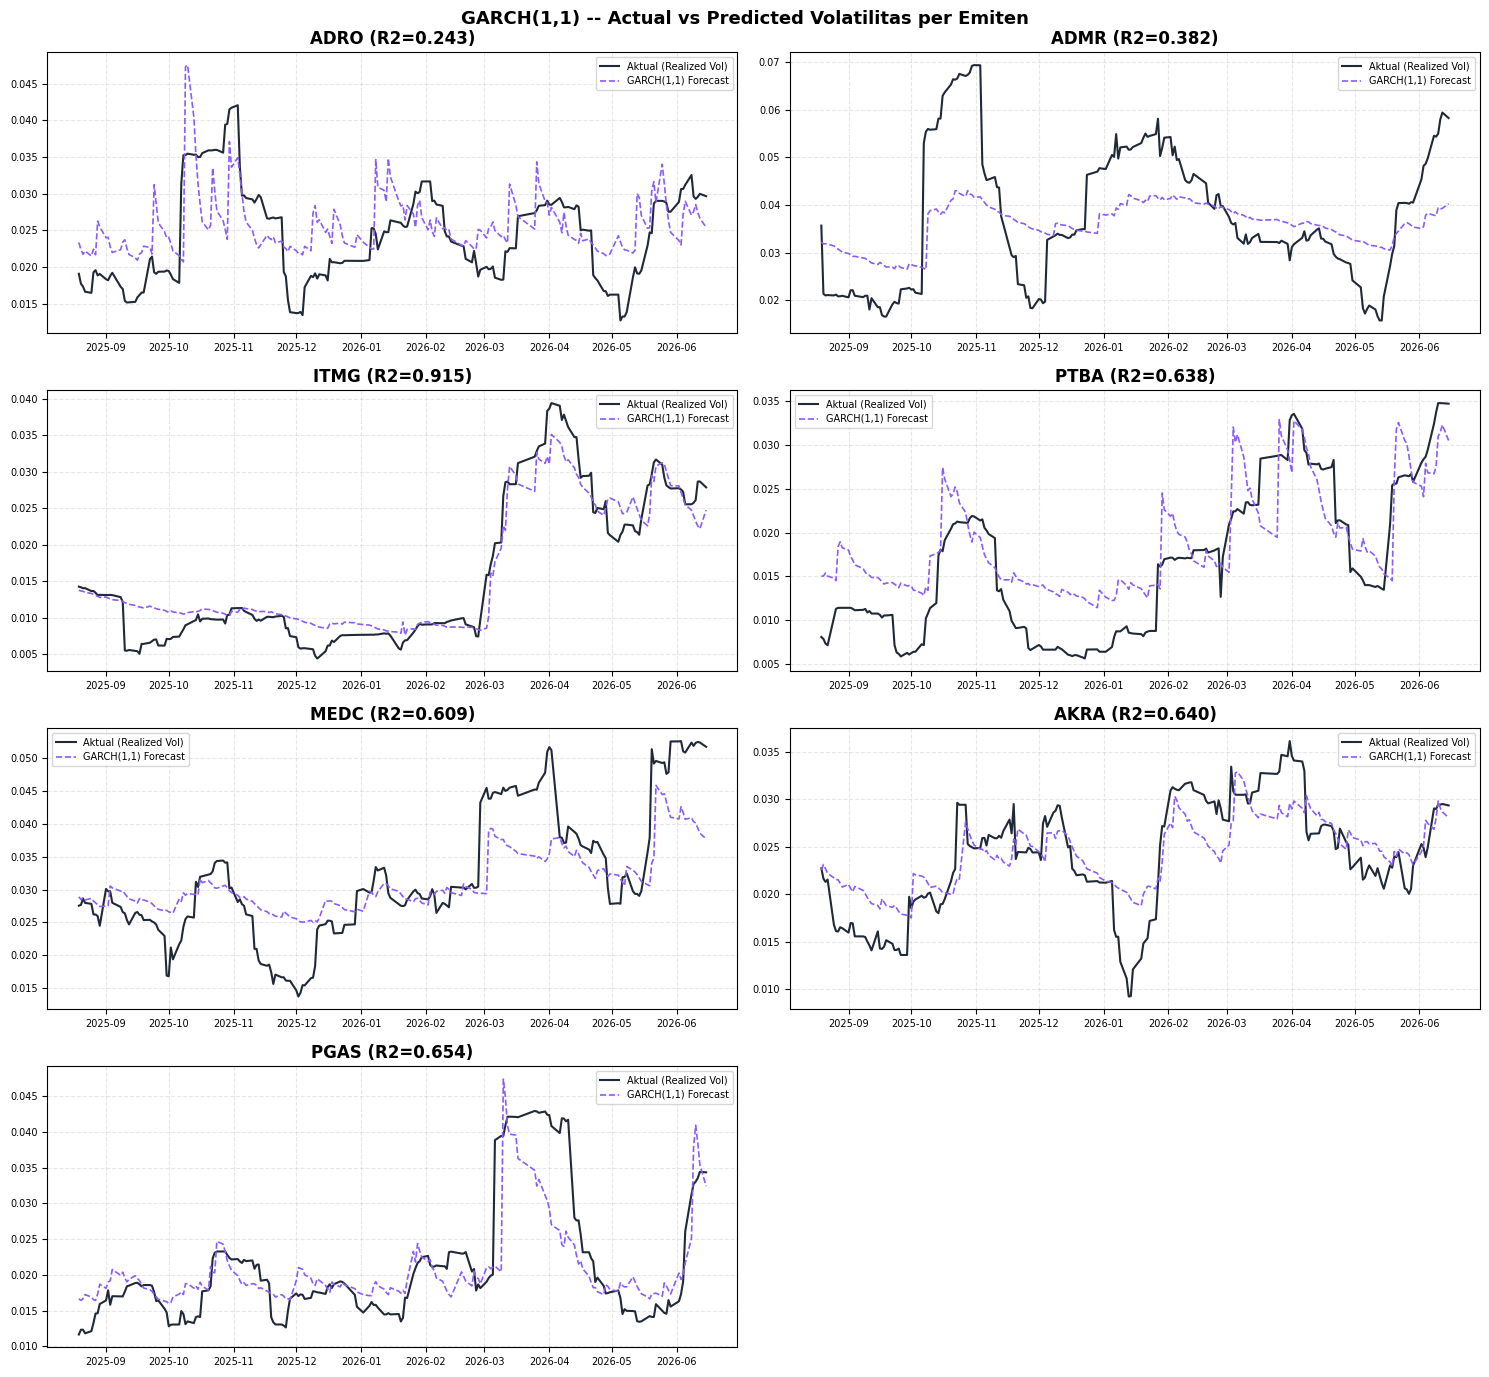

Gambar disimpan: e:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\06_dokumen_tesis\gambar\model\gambar_garch_actual_vs_predicted.png


In [6]:
print('=' * 70)
print('  VISUALISASI ACTUAL VS PREDICTED GARCH')
print('=' * 70)

emiten_ok_garch = [e for e in URUTAN_EMITEN if e in hasil_garch]
ncol = 2; nrow = int(np.ceil(len(emiten_ok_garch) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(15, 3.5 * nrow))
axes = np.array(axes).ravel()

for ax, emiten in zip(axes, emiten_ok_garch):
    m = hasil_garch[emiten]
    ax.plot(m['dates'], m['y_true'], color='#1f2937', lw=1.5, label='Aktual (Realized Vol)')
    ax.plot(m['dates'], m['y_pred'], color='#8B5CF6', lw=1.2, ls='--', label='GARCH(1,1) Forecast')
    ax.set_title(f"{emiten} (R2={m['R2']:.3f})", fontweight='bold')
    ax.legend(fontsize=7); ax.tick_params(labelsize=7)
    ax.grid(alpha=0.3, linestyle='--')

for ax in axes[len(emiten_ok_garch):]:
    ax.axis('off')

plt.suptitle('GARCH(1,1) -- Actual vs Predicted Volatilitas per Emiten',
             fontweight='bold', fontsize=13)
plt.tight_layout()
path_fig = DIR_GAMBAR / 'gambar_garch_actual_vs_predicted.png'
plt.savefig(path_fig, dpi=200, bbox_inches='tight')
plt.show()
print(f'Gambar disimpan: {path_fig}')


---
## CELL 7 — Simpan Hasil Prediksi (untuk Digabung ke EVALUASI_perbandingan)

In [7]:
print('=' * 70)
print('  SIMPAN HASIL PREDIKSI GARCH')
print('=' * 70)

df_all_garch = pd.concat([
    pd.DataFrame({
        'Date': hasil_garch[e]['dates'], 'Emiten': e,
        'Y_Aktual': hasil_garch[e]['y_true'], 'Y_Prediksi': hasil_garch[e]['y_pred'],
        'Residual': hasil_garch[e]['y_true'] - hasil_garch[e]['y_pred'],
    })
    for e in hasil_garch
], ignore_index=True)

path_hasil = DIR_FINAL / 'hasil_prediksi_garch.csv'
df_all_garch.to_csv(path_hasil, index=False, encoding='utf-8-sig')
print(f'Hasil prediksi disimpan: {path_hasil} ({len(df_all_garch)} baris)')
print()
print('CATATAN: file ini bisa dimuat di EVALUASI_perbandingan.ipynb untuk')
print('membuat perbandingan 3-way (GARCH vs XGBoost vs LSTM) yang lengkap --')
print('lihat kolom Y_Aktual/Y_Prediksi, formatnya sama dgn hasil_prediksi_lstm.csv.')


  SIMPAN HASIL PREDIKSI GARCH
Hasil prediksi disimpan: e:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\03_dataset\final\hasil_prediksi_garch.csv (1393 baris)

CATATAN: file ini bisa dimuat di EVALUASI_perbandingan.ipynb untuk
membuat perbandingan 3-way (GARCH vs XGBoost vs LSTM) yang lengkap --
lihat kolom Y_Aktual/Y_Prediksi, formatnya sama dgn hasil_prediksi_lstm.csv.


---
## CELL 8 — Kesimpulan GARCH sebagai Pembanding

In [8]:
print('=' * 70)
print('  KESIMPULAN GARCH(1,1) SEBAGAI PEMBANDING')
print('=' * 70)

if len(df_eval_garch) > 1:
    avg_row = df_eval_garch[df_eval_garch['Emiten'] == 'RATA-RATA'].iloc[0]
    print(f"Rata-rata RMSE GARCH  : {avg_row['RMSE']:.5f}")
    print(f"Rata-rata MAPE GARCH  : {avg_row['MAPE (%)']:.2f}%")
    print(f"Rata-rata R2 GARCH    : {avg_row['R2']:.4f}")
    print()
    print("Bandingkan angka di atas dengan tabel_evaluasi_xgboost.csv dan")
    print("tabel_evaluasi_lstm.csv (rata-rata RMSE/MAPE/R2) secara manual, atau")
    print("jalankan gabungan 3-way di EVALUASI_perbandingan.ipynb.")
    print()
    print("CATATAN UNTUK BAB 4/5:")
    print("- Kalau XGBoost/LSTM mengungguli GARCH: bukti kuantitatif bahwa fitur")
    print("  teknikal + sentimen (yang TIDAK dimiliki GARCH) memberi nilai tambah")
    print("  nyata dibanding model time-series klasik univariate.")
    print("- Kalau GARCH kompetitif/lebih baik di emiten tertentu: temuan valid,")
    print("  bisa didiskusikan sbg karakteristik volatilitas emiten tsb yang lebih")
    print("  cocok ditangkap proses autoregresif sederhana drpd fitur kompleks.")
    print("- GARCH TIDAK memakai sentimen (X2) -- perbandingan ini murni menguji")
    print("  \'apakah kompleksitas tambahan (fitur+ML) worth it\', bukan replikasi")
    print("  1:1 dari RM-3 (yang membandingkan XGBoost vs LSTM, keduanya dgn X1+X2).")
else:
    print("Data evaluasi GARCH belum lengkap.")


  KESIMPULAN GARCH(1,1) SEBAGAI PEMBANDING
Rata-rata RMSE GARCH  : 0.00562
Rata-rata MAPE GARCH  : 22.52%
Rata-rata R2 GARCH    : 0.5832

Bandingkan angka di atas dengan tabel_evaluasi_xgboost.csv dan
tabel_evaluasi_lstm.csv (rata-rata RMSE/MAPE/R2) secara manual, atau
jalankan gabungan 3-way di EVALUASI_perbandingan.ipynb.

CATATAN UNTUK BAB 4/5:
- Kalau XGBoost/LSTM mengungguli GARCH: bukti kuantitatif bahwa fitur
  teknikal + sentimen (yang TIDAK dimiliki GARCH) memberi nilai tambah
  nyata dibanding model time-series klasik univariate.
- Kalau GARCH kompetitif/lebih baik di emiten tertentu: temuan valid,
  bisa didiskusikan sbg karakteristik volatilitas emiten tsb yang lebih
  cocok ditangkap proses autoregresif sederhana drpd fitur kompleks.
- GARCH TIDAK memakai sentimen (X2) -- perbandingan ini murni menguji
  'apakah kompleksitas tambahan (fitur+ML) worth it', bukan replikasi
  1:1 dari RM-3 (yang membandingkan XGBoost vs LSTM, keduanya dgn X1+X2).
